# Percptron

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Implementação do perceptron

In [3]:
class Perceptron:
    def __init__(self, learning_rate=0.01, n_epochs=1000, weight_init="random"):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.weights = None
        self.weights_init = weight_init
        self.bias = None
        self.errors_per_epoch = [] #Armazena o erro a cada época

    # Inicializando os pesos de forma customizada
    def _initialize_weights(self,n_features):
        """ Inicializa os pesos de acordo com o método escolhido """
        if self.weights_init == "random":
            self.weights = np.random.rand(n_features)
            self.bias = np.random.rand()
        elif self.weights_init == "zeros":
            self.weights = np.zeros(n_features)
            self.bias = 0
        elif self.weights_init == "normal":
            self.weights = np.random.randn(n_features) * 0.01 #Pequenos valores gaussianos
            self.bias = np.random.randn() * 0.01
        else:
            raise ValueError("Opção inválida para inicialização dos pesos")

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self._initialize_weights(n_features) # Inicializa os pesos dinamicamente
        self.bias = 0

        for epoch in range(self.n_epochs):
            errors = 0 # Cortador de erros por época

            for i in range(n_samples):
                linear_output = np.dot(X[i], self.weights) + self.bias
                y_pred = np.sign(linear_output)

                # Atualização dos pesos se houver erro
                if y_pred != y[i]:
                    self.weights += self.learning_rate *y[i] * X[i]
                    self.bias += self.learning_rate * y[i]
                    errors += 1 # Incrementa erro se classificação errada

            # Armazena a taxa de erro (erros / total de amostras)
            self.errors_per_epoch.append(errors / n_samples)

            # Parada antecipada se não houver erros
            if errors == 0:
                break

        # Após o treinamento, clacular e exibir estatísticas
        self._print_training_summary(X, y, epoch + 1)

    # Método para exibir a acurácia e pesos finais 
    def _print_training_summary(self, X, y, epochs):
        y_pred = self.predict(X)
        accuracy = np.mean(y_pred == y) * 100
        std_dev = np.std(self.weights)

        print("\n==== Resumo do Treinamento ====")
        print(f"Acurácia no conjunto de treino: {accuracy:.2f}%")
        print(f"Número total de épocas: {epochs}")
        print(f"Pesos finais aprendidos: {self.weights}")
        print(f"Bias final: {self.bias}")
        print("==================================")

    # Retorna a predição com base no treinamento do Perceptron
    def predict(self, X):
        return np.sign(np.dot(X, self.weights) + self.bias)

    # Faz previsões e, se os rótulos foresm fornecidos, exibe métricas
    # Coloque esse método (não está nos slides)
    def predict2(self, X, y, y_true=None):
        y_pred = np.sign(np.dot(X, self.weights) + self.bias)

        #Se y_true for fornecido, calcular métricas de avaliação
        if y_true is not None:
            self.predict_summary(X, y_true, 0, "Teste")

        return y_pred

    #Calculando as métricas da predição
    def predict_summary(self, X, y, epochs, phase):
        """ Método para exibir a acurácia, desvio padrão e pesos finais """
        y_pred = np.sign(np.dot(X, self.weights) + self.bias)
        accuracy = np.mean(y_pred == y) * 100
        std_dev = np.std(self.weights)

        print(f"\n==== Resumo do {phase} ====")
        print(f"Acurácia no conjunto de {phase.lower()}: {accuracy:.2f}%")
        print(f"Desvio Padrão dos Pesos: {std_dev:.5f}")
        if epochs > 0:
            print(f"Número total de épocas: {epochs}")
        print(f"Pesos finais aprendidos: {self.weights}")
        print(f"Bias final: {self.bias}")
        print("==================================")

        # Plota o gráfico da evolução dos erros ao longo das écopas de treinamento
    def plot_error(self):
        plt.figure(figsize=(8, 4))
        plt.plot(self.errors_per_epoch, marker='o', linestyle='-')
        plt.xlabel("Épocas")
        plt.ylabel("Taxa de Erro")
        plt.title("Evolução do erro ao longo das épocas")
        plt.grid()
        plt.show()

In [4]:
# Gráfico da "fronteira" gerado pelo Perceptron
def plot_decision_boundary(X, y, model, title="Fronteira de Decisão do Perceptron"):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
    
    # Predição para cada ponto da grade
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Criar o gráfico
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="K")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title(title)
    plt.show()

In [5]:
# Função para plotar lado a lado: dataset e fronteira de decisão
def plot_comparison(X, y, model):
    # Criar uma grade para o plano cartesiano
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

    # Predição para cada ponto da grade
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Criar os subplots (1 linha, 2 colunas)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Subplot 1: Fronteira de decisão
    axes[0].contourf(xx, yy, Z, alpha=0.3)
    axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    axes[0].set_xlabel("X1")
    axes[0].set_ylabel("X2")
    axes[0].set_title("Fronteira de Decisão do Perceptron")

    # Subplot 2: Apenas dados
    axes[1].scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    axes[1].set_xlabel("X1")
    axes[1].set_ylabel("X2")
    axes[1].set_title("Distribuição dos Dados do Dataset")

    plt.tight_layout()
    plt.show()


==== Resumo do Treinamento ====
Acurácia no conjunto de treino: 97.14%
Número total de épocas: 100
Pesos finais aprendidos: [-0.65433528  0.71596706]
Bias final: 0.30000000000000004


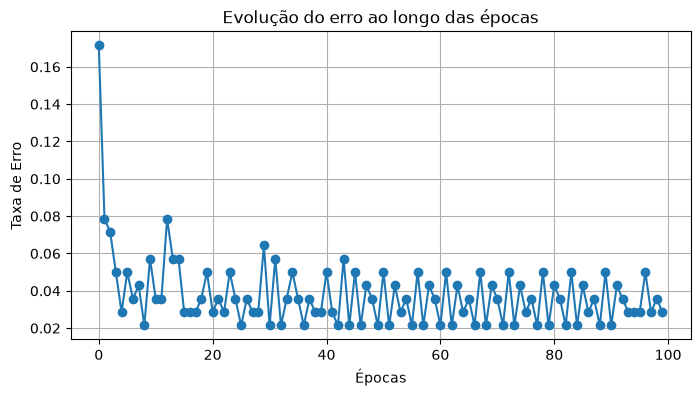

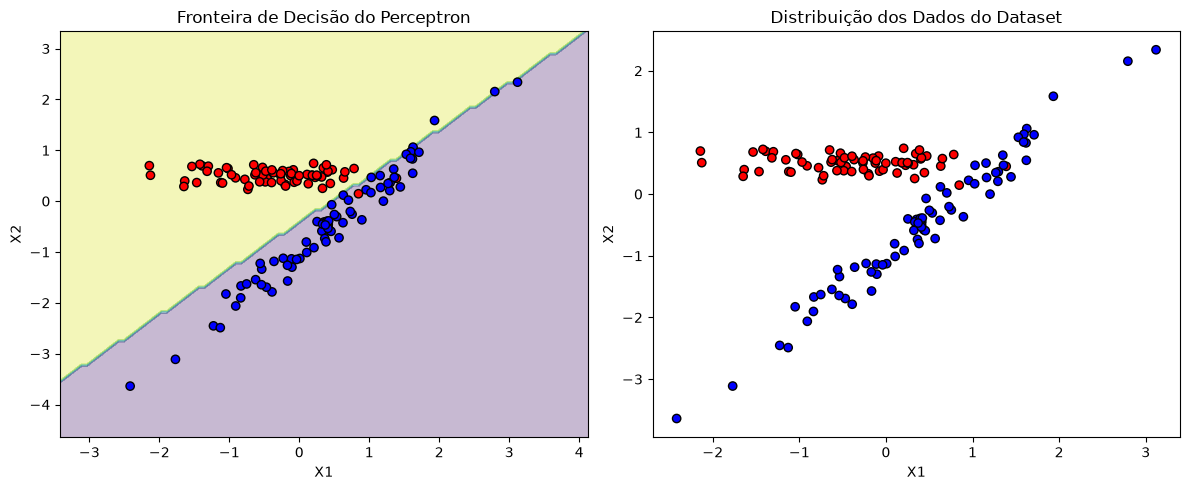

In [6]:
# Dataset 1 - Importando e cisualizando o dataset de Treino
train_dataset1 = np.loadtxt("train_dataset1.csv", delimiter=",", skiprows=1, dtype=float)

X = train_dataset1[:, :2]
y = train_dataset1[:, 2]

y = np.where(y == -1, -1, 1)

perceptron = Perceptron(learning_rate=0.1, n_epochs=100)

perceptron.fit(X, y)

y_pred = perceptron.predict2(X, y)

perceptron.plot_error()

print("")

plot_comparison(X, y, perceptron)

## Testando o Perceptron  com os dados do Dataset 1


==== Resumo do Teste ====
Acurácia no conjunto de teste: 93.33%
Desvio Padrão dos Pesos: 0.68515
Pesos finais aprendidos: [-0.65433528  0.71596706]
Bias final: 0.30000000000000004


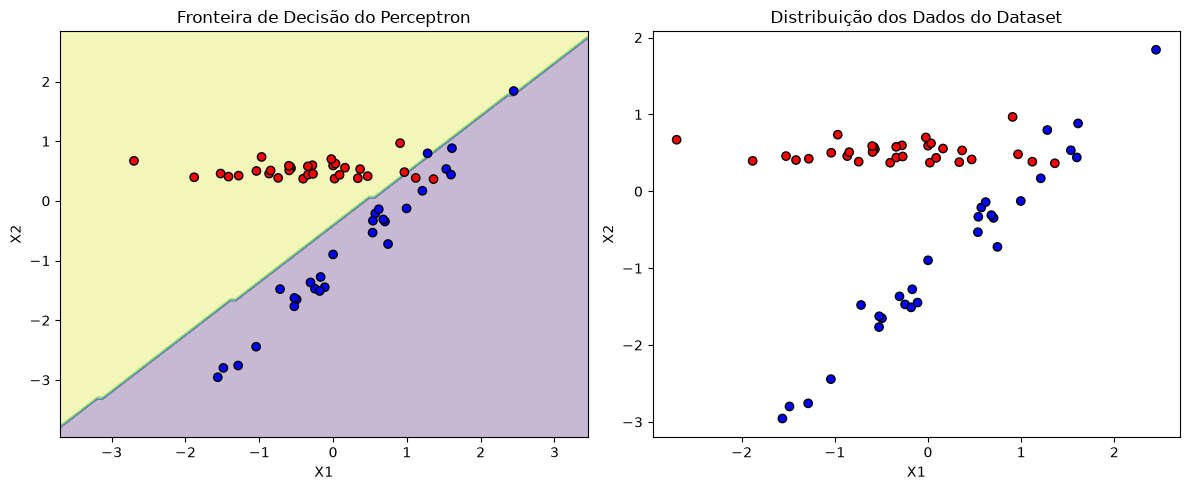

In [7]:
# Dataset 1 - Importando e cisualizando o dataset de Treino
test_dataset1 = np.loadtxt("test_dataset1.csv", delimiter=",", skiprows=1, dtype=float)

X_test = test_dataset1[:, :2]
y_test = test_dataset1[:, 2]
y_test = np.where(y_test == -1, -1, 1)

perceptron.predict2(X_test, y, y_test)

plot_comparison(X_test, y_test, perceptron)


==== Resumo do Treinamento ====
Acurácia no conjunto de treino: 49.14%
Número total de épocas: 100
Pesos finais aprendidos: [ 0.0644102 -0.1085529]
Bias final: 0.0


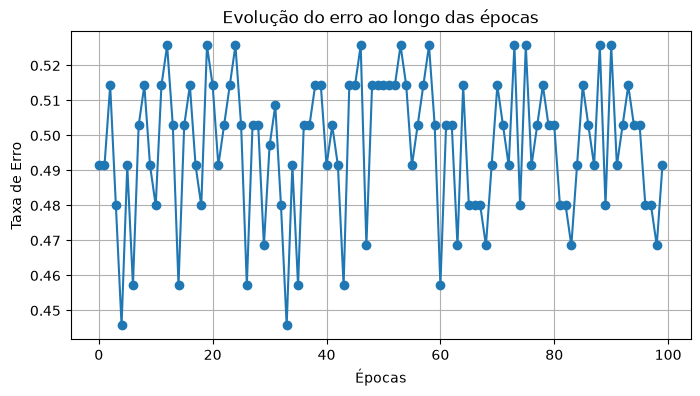

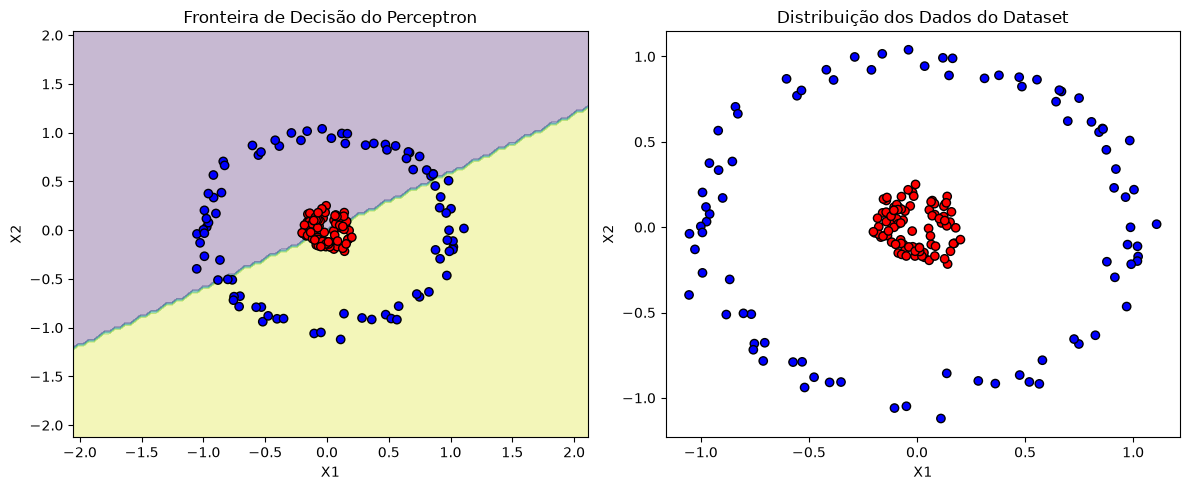

In [ ]:
# Dataset 2
train_dataset2 = np.loadtxt("train_dataset2.csv", delimiter=",", skiprows=1, dtype=float)

X = train_dataset2[:, :2]
y = train_dataset2[:, 2]

y = np.where(y == -1, -1, 1)

perceptron = Perceptron(learning_rate=0.1, n_epochs=100)

perceptron.fit(X, y)

y_pred = perceptron.predict2(X, y)

perceptron.plot_error()

print("")

plot_comparison(X, y, perceptron)


==== Resumo do Teste ====
Acurácia no conjunto de teste: 49.33%
Desvio Padrão dos Pesos: 0.08648
Pesos finais aprendidos: [ 0.0644102 -0.1085529]
Bias final: 0.0


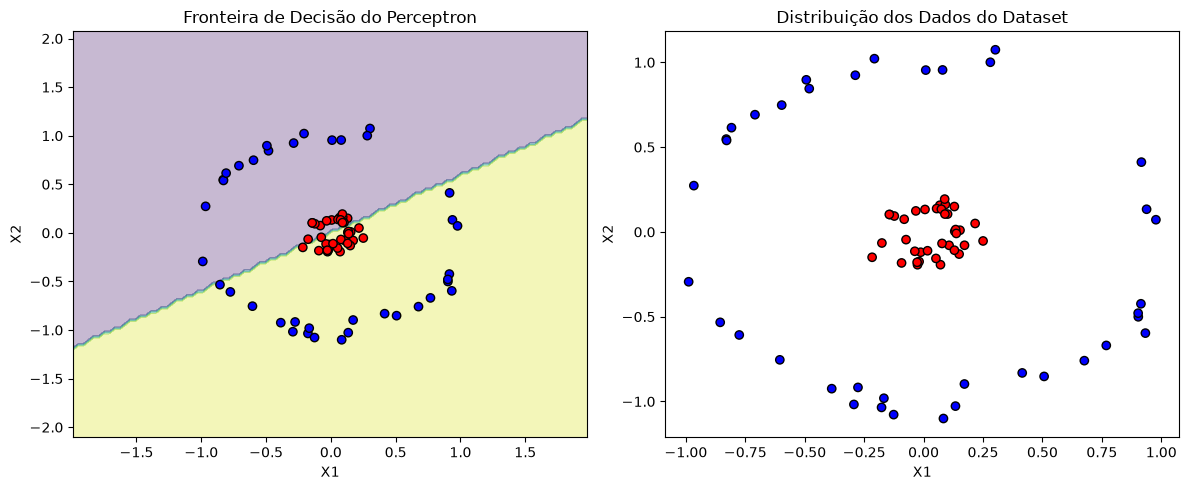

In [ ]:
# Dataset 2
test_dataset2 = np.loadtxt("test_dataset2.csv", delimiter=",", skiprows=1, dtype=float)

X_test = test_dataset2[:, :2]
y_test = test_dataset2[:, 2]
y_test = np.where(y_test == -1, -1, 1)

perceptron.predict2(X_test, y, y_test)

plot_comparison(X_test, y_test, perceptron)

## Treinando o Perceptron com os dados do Dataset 3
 
| #  | Taxa de Aprendizado | Épocas |
|----|---------------------|--------|
| 1  | 0.1               | 100    |
| 2  | 0.1               | 200    |
| 3  | 0.001             | 100    |
| 4  | 0.001             | 200    |
| 5  | 0.0001            | 100    |
| 6  | 0.0001            | 200    |

Cenário 1 - Treinamento:0.1 | Épocas 100

==== Resumo do Treinamento ====
Acurácia no conjunto de treino: 91.84%
Número total de épocas: 100
Pesos finais aprendidos: [-0.10186253 -0.11592375 -0.13057476 -0.43194299  0.18646009 -0.14999544
  0.10683453  0.35326094 -0.05769034  1.24861699]
Bias final: 0.10000000000000003


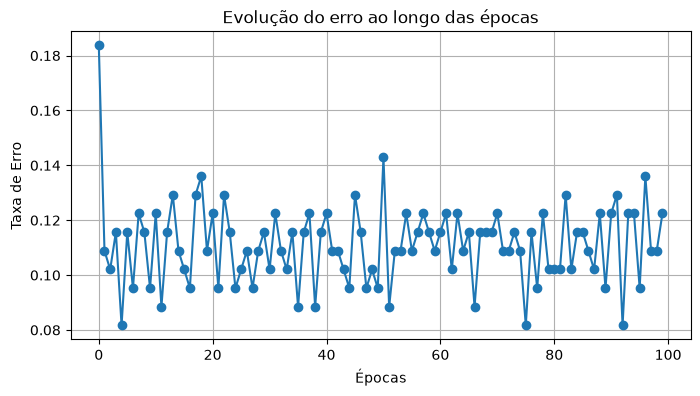


Cenário 2 - Treinamento:0.1 | Épocas 200

==== Resumo do Treinamento ====
Acurácia no conjunto de treino: 91.84%
Número total de épocas: 200
Pesos finais aprendidos: [ 0.13980294 -0.21842045 -0.21133311 -0.24944131  0.13023024  0.12734135
 -0.13594654  0.3396443  -0.13163009  1.15189485]
Bias final: 0.20000000000000004


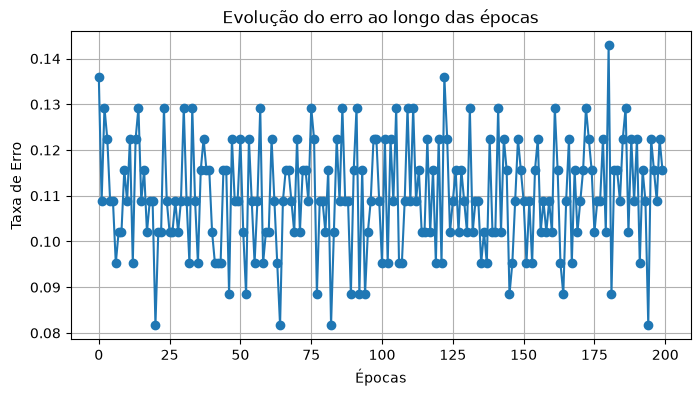


Cenário 3 - Treinamento:0.001 | Épocas 100

==== Resumo do Treinamento ====
Acurácia no conjunto de treino: 93.88%
Número total de épocas: 100
Pesos finais aprendidos: [ 0.13345559  0.09340047 -0.12951744  0.04382707  0.04326965 -0.03415333
  0.17925699  0.15902711 -0.10952885  0.66848314]
Bias final: -0.06000000000000004


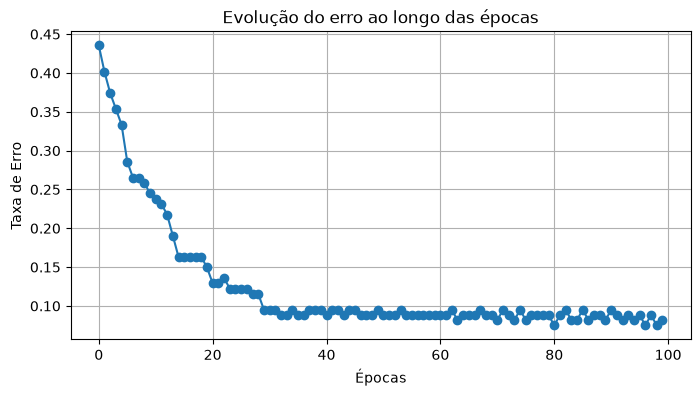


Cenário 4 - Treinamento:0.001 | Épocas 200

==== Resumo do Treinamento ====
Acurácia no conjunto de treino: 94.56%
Número total de épocas: 200
Pesos finais aprendidos: [ 0.05307035  0.01672642 -0.1106405  -0.10841115 -0.01959454 -0.04897511
  0.04653745  0.14298551  0.01315158  0.52673798]
Bias final: 0.08900000000000008


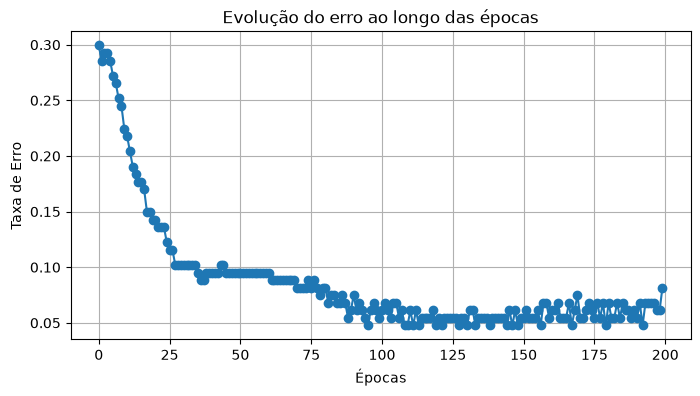


Cenário 5 - Treinamento:0.0001 | Épocas 100

==== Resumo do Treinamento ====
Acurácia no conjunto de treino: 73.47%
Número total de épocas: 100
Pesos finais aprendidos: [0.18957474 0.68343788 0.3972101  0.26256113 0.4141282  0.12601507
 0.66990591 0.81055266 0.32422646 1.18139727]
Bias final: -0.07130000000000102


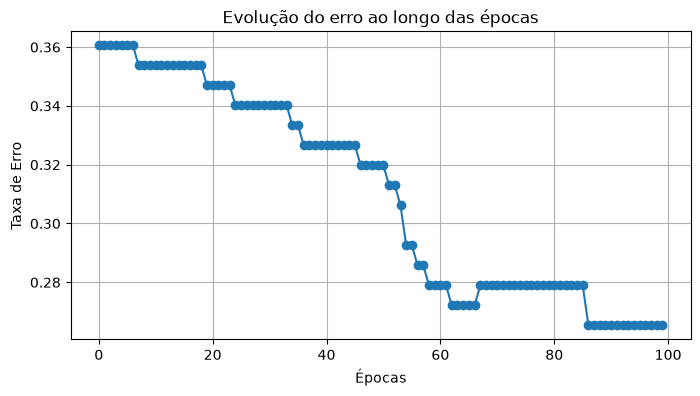


Cenário 6 - Treinamento:0.0001 | Épocas 200

==== Resumo do Treinamento ====
Acurácia no conjunto de treino: 80.27%
Número total de épocas: 200
Pesos finais aprendidos: [0.17414653 0.18583052 0.47356242 0.27238452 0.37565436 0.51203254
 0.54660109 0.50368479 0.1097891  0.98342008]
Bias final: -0.15299999999999947


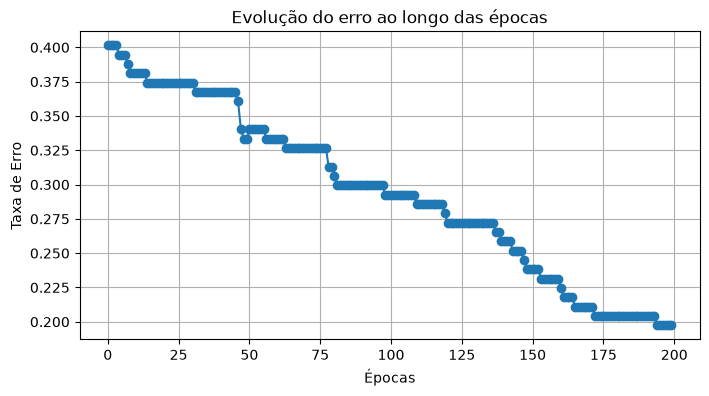

In [21]:
# Dataset 3
train_dataset3 = np.loadtxt("train_dataset3.csv", delimiter=",", skiprows=1, dtype=float)

X = train_dataset3[:, :-1]
y = train_dataset3[:, -1]

y = np.where(y == -1, -1, 1)

perceptron_cenario1 = Perceptron(learning_rate=0.1, n_epochs=100)
perceptron_cenario2 = Perceptron(learning_rate=0.1, n_epochs=200)
perceptron_cenario3 = Perceptron(learning_rate=0.001, n_epochs=100)
perceptron_cenario4 = Perceptron(learning_rate=0.001, n_epochs=200)
perceptron_cenario5 = Perceptron(learning_rate=0.0001, n_epochs=100)
perceptron_cenario6 = Perceptron(learning_rate=0.0001, n_epochs=200)

print("Cenário 1 - Treinamento:0.1 | Épocas 100")
perceptron_cenario1.fit(X, y)
perceptron_cenario1.plot_error()
print("")

print("Cenário 2 - Treinamento:0.1 | Épocas 200")
perceptron_cenario2.fit(X, y)
perceptron_cenario2.plot_error()
print("")

print("Cenário 3 - Treinamento:0.001 | Épocas 100")
perceptron_cenario3.fit(X, y)
perceptron_cenario3.plot_error()
print("")

print("Cenário 4 - Treinamento:0.001 | Épocas 200")
perceptron_cenario4.fit(X, y)
perceptron_cenario4.plot_error()
print("")

print("Cenário 5 - Treinamento:0.0001 | Épocas 100")
perceptron_cenario5.fit(X, y)
perceptron_cenario5.plot_error()
print("")

print("Cenário 6 - Treinamento:0.0001 | Épocas 200")
perceptron_cenario6.fit(X, y)
perceptron_cenario6.plot_error()
print("")

In [22]:
# Dataset 3
test_dataset3 = np.loadtxt("test_dataset3.csv", delimiter=",", skiprows=1, dtype=float)

X_test = test_dataset3[:, :-1]
y_test = test_dataset3[:, -1]

y_test = np.where(y_test == -1, -1, 1)

print("Cenário 1 - Treinamento:0.1 | Épocas 100")
perceptron_cenario1.predict2(X_test, y, y_test)
print("")

print("Cenário 2 - Treinamento:0.1 | Épocas 200")
perceptron_cenario2.predict2(X_test, y, y_test)
print("")

print("Cenário 3 - Treinamento:0.001 | Épocas 100")
perceptron_cenario3.predict2(X_test, y, y_test)
print("")

print("Cenário 4 - Treinamento:0.001 | Épocas 200")
perceptron_cenario4.predict2(X_test, y, y_test)
print("")

print("Cenário 5 - Treinamento:0.0001 | Épocas 100")
perceptron_cenario5.predict2(X_test, y, y_test)
print("")

print("Cenário 6 - Treinamento:0.0001 | Épocas 200")
perceptron_cenario6.predict2(X_test, y, y_test)
print("")

Cenário 1 - Treinamento:0.1 | Épocas 100

==== Resumo do Teste ====
Acurácia no conjunto de teste: 82.54%
Desvio Padrão dos Pesos: 0.43600
Pesos finais aprendidos: [-0.10186253 -0.11592375 -0.13057476 -0.43194299  0.18646009 -0.14999544
  0.10683453  0.35326094 -0.05769034  1.24861699]
Bias final: 0.10000000000000003

Cenário 2 - Treinamento:0.1 | Épocas 200

==== Resumo do Teste ====
Acurácia no conjunto de teste: 90.48%
Desvio Padrão dos Pesos: 0.39957
Pesos finais aprendidos: [ 0.13980294 -0.21842045 -0.21133311 -0.24944131  0.13023024  0.12734135
 -0.13594654  0.3396443  -0.13163009  1.15189485]
Bias final: 0.20000000000000004

Cenário 3 - Treinamento:0.001 | Épocas 100

==== Resumo do Teste ====
Acurácia no conjunto de teste: 80.95%
Desvio Padrão dos Pesos: 0.21327
Pesos finais aprendidos: [ 0.13345559  0.09340047 -0.12951744  0.04382707  0.04326965 -0.03415333
  0.17925699  0.15902711 -0.10952885  0.66848314]
Bias final: -0.06000000000000004

Cenário 4 - Treinamento:0.001 | Época

# OBS: 
Os resultados mudam a cada vez que é rodada a célula, porque ele pode inicializar com o peso sendo aleatório, com zero ou normal.